In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


In [2]:
!pip install -q wandb lightgbm

import os, re, string, warnings, gc, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from collections import Counter

import wandb

warnings.filterwarnings('ignore')
plt.style.use('ggplot')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")


Device: cuda


In [3]:
wandb.login(key="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")

import os, time, wandb

import os, time, wandb


os.environ["WANDB_MODE"]              = "offline"  
os.environ["WANDB_SILENT"]            = "true"
os.environ["WANDB_CONSOLE"]           = "off"      
os.environ["WANDB_DISABLE_SERVICE"]   = "false"
os.environ["WANDB__DISABLE_STATS"]    = "true"     
os.environ["WANDB__DISABLE_META"]     = "true"

# Build Settings compatibly across wandb versions
try:
    _settings = wandb.Settings(x_stats_sampling_interval=60, console="off")
except TypeError:
    try:
        _settings = wandb.Settings(_disable_stats=True, console="off")
    except TypeError:
        _settings = None

run = wandb.init(
    project="smart-mcq-solver",
    name=f"all-models-{time.strftime('%m%d-%H%M')}",
    config={"metric": "MAP@3"},
    settings=_settings,
)
print(f"Single offline run: {run.name} — system tracking off, offline")


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
wandb: WARNING Changes to your `wandb` environment variables will be ignored because your `wandb` session has already started. For more information on how to modify your settings with `wandb.init()` arguments, please refer to https://wandb.me/wandb-init.
wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260729_115931-fuudbtok
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run all-models-0729-1159
wandb: ⭐️ View project at htt

Single offline run: all-models-0729-1159 — system tracking off, offline


In [4]:

train_raw = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
test_raw  = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')
sample_sub = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv')

print(f"Train: {train_raw.shape}")
print(f"Test:  {test_raw.shape}")
train_raw.head(3)


Train: (2000, 8)
Test:  (500, 7)


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C


In [5]:
# 1.1 Null 
print("=== Null values ===")
print(train_raw.isnull().sum())
print(f"\nTest nulls: {test_raw.isnull().sum().sum()}")

# Check for hidden NaN-like strings
nan_patterns = ['nan', 'none', 'null', 'n/a', 'na', '']
for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
    suspicious = train_raw[train_raw[col].astype(str).str.strip().str.lower().isin(nan_patterns)]
    if len(suspicious) > 0:
        print(f"\n⚠ {col}: {len(suspicious)} suspicious values")
        print(suspicious[['id', col]].head())

print("\n Null audit complete")


=== Null values ===
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

Test nulls: 0

 Null audit complete


In [6]:
# ── 1.2 Defensive Cleaning ──
def clean_dataframe(df):
    df = df.copy()
    text_cols = ['prompt', 'A', 'B', 'C', 'D', 'E']
    
    for col in text_cols:
        df[col] = df[col].fillna('')
        df[col] = df[col].astype(str)
        df[col] = df[col].str.strip()
        df[col] = df[col].str.replace(r'\s+', ' ', regex=True)
        df[col] = df[col].replace(
            {'nan': '', 'None': '', 'null': '', 'N/A': '', 'NA': ''},
            regex=False
        )
       
        df.loc[df[col] == '', col] = '[no text]'
    
 
    if 'answer' in df.columns:
        df['answer'] = df['answer'].str.strip().str.upper()
        assert df['answer'].isin(['A','B','C','D','E']).all(), "Invalid answer values!"
    
    return df

train = clean_dataframe(train_raw)
test  = clean_dataframe(test_raw)

print(f"Cleaned — Train: {train.shape}, Test: {test.shape}")
print(f"Any remaining nulls: {train.isnull().sum().sum() + test.isnull().sum().sum()}")

wandb.log({"data/train_rows": len(train), "data/test_rows": len(test),
           "data/null_count": 0})


Cleaned — Train: (2000, 8), Test: (500, 7)
Any remaining nulls: 0


In [7]:

def normalize_text(text):
    """Lowercase, remove punctuation, collapse whitespace."""
    text = str(text).lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\s+', ' ', text).strip()
    return text

INSTRUCTION_PREFIXES = [
    r'^pick the best possible answer:\s*',
    r'^select the most accurate option:\s*',
    r'^identify the correct statement[^:]*:\s*',
    r'^determine the correct option:\s*',
    r'^which of the following is correct[^:]*:\s*',
    r'^choose the correct answer:\s*',
]

def extract_core_question(prompt):
    text = str(prompt).strip()
    for pattern in INSTRUCTION_PREFIXES:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)
    # Remove trailing instruction noise
    text = re.sub(r'\s*(among the listed options|carefully|from the options below)\.?\s*$', '', text, flags=re.IGNORECASE)
    return text.strip()

train['prompt_clean'] = train['prompt'].apply(normalize_text)
train['core_question'] = train['prompt'].apply(extract_core_question)
test['prompt_clean'] = test['prompt'].apply(normalize_text)
test['core_question'] = test['prompt'].apply(extract_core_question)

print("Sample cleaned prompt:")
print(f"  Original: {train.iloc[0]['prompt'][:100]}...")
print(f"  Core:     {train.iloc[0]['core_question'][:100]}...")


Sample cleaned prompt:
  Original: Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and ...
  Core:     What is Martin Heidegger's view on the relationship between time and human existence?...


## Part 2 — Exploratory Data Analysis
Answer distribution, option-length bias, question phrasing types, and how much the
test set overlaps the training set.

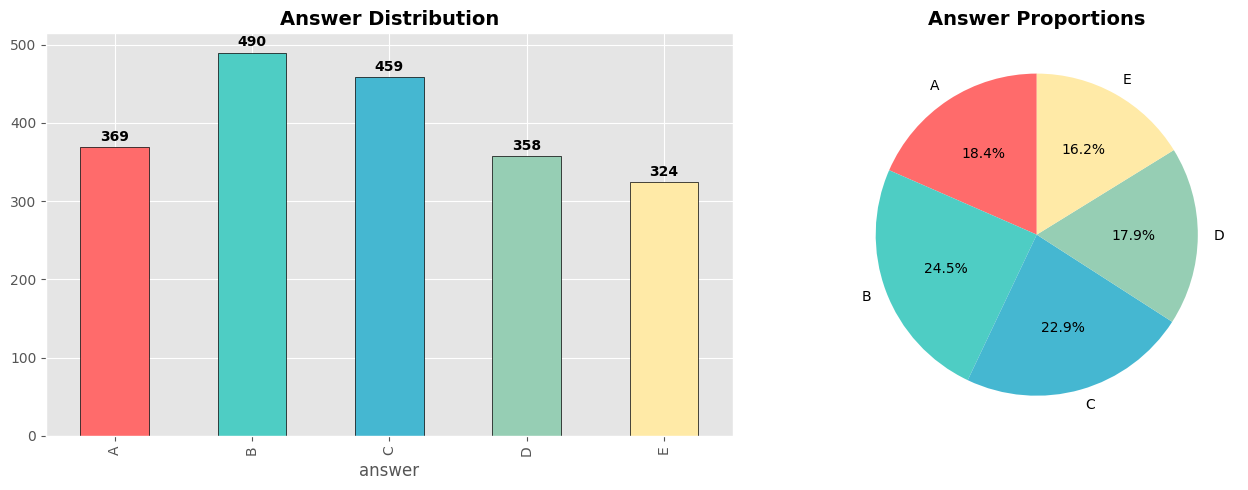

Frequency order: ['B', 'C', 'A', 'D', 'E'] → [490, 459, 369, 358, 324]


In [8]:
# ── 2.1 Answer Distribution ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
freq = train['answer'].value_counts().sort_index()
colors = ['#FF6B6B','#4ECDC4','#45B7D1','#96CEB4','#FFEAA7']

freq.plot(kind='bar', ax=axes[0], color=colors, edgecolor='black', linewidth=0.5)
axes[0].set_title('Answer Distribution', fontsize=14, fontweight='bold')
for i, v in enumerate(freq.values):
    axes[0].text(i, v+8, str(v), ha='center', fontweight='bold')

freq.plot(kind='pie', ax=axes[1], colors=colors, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Answer Proportions', fontsize=14, fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('eda_answer_dist.png', dpi=150, bbox_inches='tight')
wandb.log({"eda/answer_distribution": wandb.Image('eda_answer_dist.png')})
plt.show()

freq_order = freq.sort_values(ascending=False).index.tolist()
print(f"Frequency order: {freq_order} → {freq.sort_values(ascending=False).values.tolist()}")


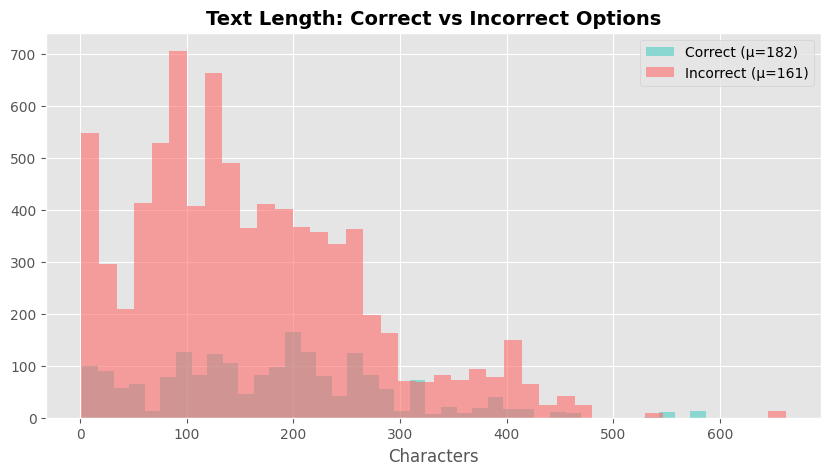

Correct answers are ~13.2% longer on average


In [9]:
# ── 2.2 Correct vs Incorrect Option Length ──
correct_lens, incorrect_lens = [], []
for _, row in train.iterrows():
    for opt in ['A','B','C','D','E']:
        l = len(str(row[opt]))
        (correct_lens if opt == row['answer'] else incorrect_lens).append(l)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(correct_lens, bins=40, alpha=0.6, label=f'Correct (μ={np.mean(correct_lens):.0f})', color='#4ECDC4')
ax.hist(incorrect_lens, bins=40, alpha=0.6, label=f'Incorrect (μ={np.mean(incorrect_lens):.0f})', color='#FF6B6B')
ax.set_title('Text Length: Correct vs Incorrect Options', fontsize=14, fontweight='bold')
ax.set_xlabel('Characters'); ax.legend()
plt.savefig('eda_length_bias.png', dpi=150, bbox_inches='tight')
wandb.log({"eda/length_bias": wandb.Image('eda_length_bias.png')})
plt.show()

print(f"Correct answers are ~{(np.mean(correct_lens)/np.mean(incorrect_lens)-1)*100:.1f}% longer on average")


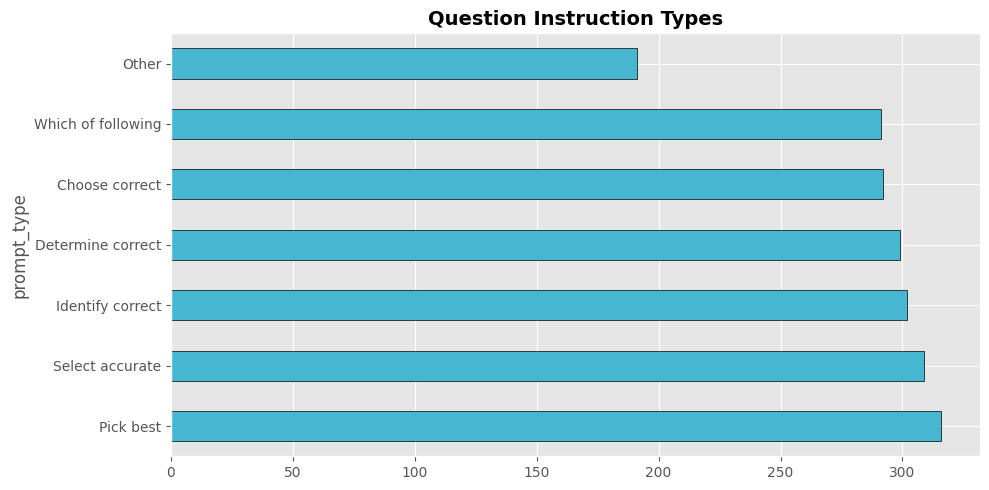

In [10]:
# ── 2.3 Prompt Type Distribution ──
def get_prompt_type(prompt):
    p = str(prompt).lower()
    if p.startswith('pick the best'): return 'Pick best'
    if p.startswith('select the most'): return 'Select accurate'
    if p.startswith('identify'): return 'Identify correct'
    if p.startswith('determine'): return 'Determine correct'
    if p.startswith('which of'): return 'Which of following'
    if p.startswith('choose'): return 'Choose correct'
    return 'Other'

train['prompt_type'] = train['prompt'].apply(get_prompt_type)

fig, ax = plt.subplots(figsize=(10, 5))
train['prompt_type'].value_counts().plot(kind='barh', ax=ax, color='#45B7D1', edgecolor='black')
ax.set_title('Question Instruction Types', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_prompt_types.png', dpi=150, bbox_inches='tight')
wandb.log({"eda/prompt_types": wandb.Image('eda_prompt_types.png')})
plt.show()


In [11]:
# ── 2.4 Train–Test Overlap ──
def make_fingerprint(row):
    return '|||'.join(str(row[o]).strip() for o in ['A','B','C','D','E'])

train['fingerprint'] = train.apply(make_fingerprint, axis=1)
test['fingerprint']  = test.apply(make_fingerprint, axis=1)

exact_overlap = test['fingerprint'].isin(set(train['fingerprint'])).sum()
print(f"Test ↔ Train exact match: {exact_overlap}/{len(test)} ({exact_overlap/len(test)*100:.1f}%)")

wandb.log({"eda/train_test_exact_overlap": exact_overlap,
           "eda/unique_train_prompts": train['prompt'].nunique()})


Test ↔ Train exact match: 458/500 (91.6%)


---
## Part 3 — Validation Split & Evaluation Metrics

The dataset contains **duplicate questions**, so a random split would put copies of the
same question in both train and validation — validation would then measure memorisation
rather than generalisation.

Every model below is evaluated on this same split using **accuracy (rank-1)**,
**macro-F1**, and **MAP@3**.

In [12]:
# ── MAP@3 Utilities ──
options = ['A','B','C','D','E']

def map_at_3(truth, preds):
    score, hits = 0.0, 0
    for i, p in enumerate(preds[:3]):
        if p == truth:
            hits += 1
            score += hits / (i + 1)
    return score

def evaluate_map3(truths, all_preds):
    return np.mean([map_at_3(t, p) for t, p in zip(truths, all_preds)])

def scores_to_preds(id_scores_dict, id_list):
    """Convert {id: [5 scores]} → list of top-3 option lists."""
    preds = []
    for qid in id_list:
        scores = id_scores_dict[qid]
        ranked = [options[i] for i in np.argsort(scores)[::-1]][:3]
        preds.append(ranked)
    return preds


Unique question groups: 588 (out of 2000 rows)
Split — train: 1624, val: 376, group overlap: 0 ✅

Answer label distribution (train vs validation):
        Train_count  Train_%  Val_count  Val_%
answer                                        
A               296     18.2         73   19.4
B               428     26.4         62   16.5
C               374     23.0         85   22.6
D               284     17.5         74   19.7
E               242     14.9         82   21.8


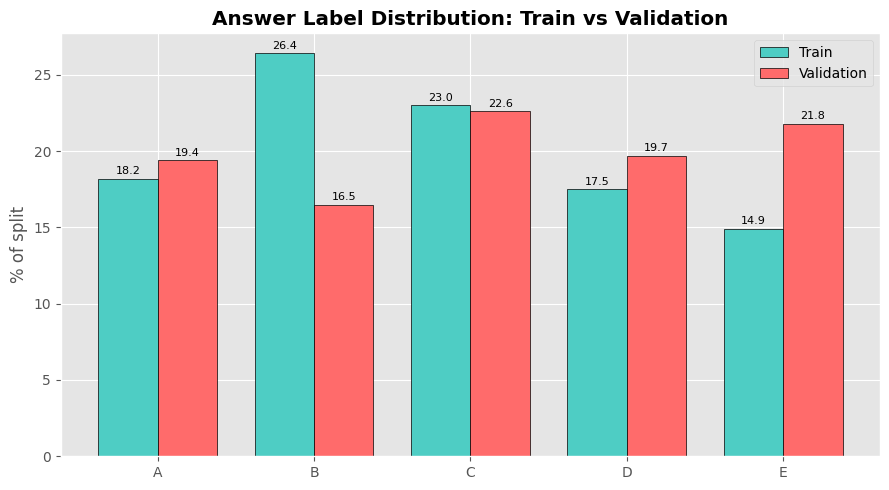


Max train-val distribution gap: 9.9% (some imbalance)


In [13]:

from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

def question_fingerprint(row):
    parts = [str(row[o]).strip().lower() for o in options]
    return '|||'.join(parts)

question_groups = train.apply(question_fingerprint, axis=1).values
y_labels = train['answer'].values

print(f"Unique question groups: {len(set(question_groups))} (out of {len(train)} rows)")

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
dl_train_idx, dl_val_idx = next(sgkf.split(train, y_labels, groups=question_groups))
dl_train_idx, dl_val_idx = list(dl_train_idx), list(dl_val_idx)


tr_g = set(question_groups[dl_train_idx])
va_g = set(question_groups[dl_val_idx])
assert len(tr_g & va_g) == 0, "LEAKAGE: shared question group across split!"
print(f"Split — train: {len(dl_train_idx)}, val: {len(dl_val_idx)}, group overlap: {len(tr_g & va_g)} ✅")

# ── Report answer label distribution in TRAIN vs VALIDATION ──
train_dist = train.iloc[dl_train_idx]['answer'].value_counts().reindex(options).fillna(0).astype(int)
val_dist   = train.iloc[dl_val_idx]['answer'].value_counts().reindex(options).fillna(0).astype(int)

dist_df = pd.DataFrame({
    'Train_count': train_dist,
    'Train_%': (train_dist / train_dist.sum() * 100).round(1),
    'Val_count': val_dist,
    'Val_%': (val_dist / val_dist.sum() * 100).round(1),
})
print("\nAnswer label distribution (train vs validation):")
print(dist_df)

# Visualize
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(options)); w = 0.38
ax.bar(x - w/2, dist_df['Train_%'], w, label='Train', color='#4ECDC4', edgecolor='black')
ax.bar(x + w/2, dist_df['Val_%'],   w, label='Validation', color='#FF6B6B', edgecolor='black')
ax.set_xticks(x); ax.set_xticklabels(options)
ax.set_ylabel('% of split'); ax.set_title('Answer Label Distribution: Train vs Validation', fontweight='bold')
ax.legend()
for i, (t, v) in enumerate(zip(dist_df['Train_%'], dist_df['Val_%'])):
    ax.text(i - w/2, t + 0.3, f'{t}', ha='center', fontsize=8)
    ax.text(i + w/2, v + 0.3, f'{v}', ha='center', fontsize=8)
plt.tight_layout()
plt.savefig('label_distribution.png', dpi=150, bbox_inches='tight')
wandb.log({"split/label_distribution": wandb.Image('label_distribution.png')})
plt.show()

# Flag imbalance
max_gap = (dist_df['Train_%'] - dist_df['Val_%']).abs().max()
print(f"\nMax train-val distribution gap: {max_gap:.1f}% "
      f"({'well balanced ' if max_gap < 3 else 'some imbalance'})")


In [14]:
# ── Shared Evaluation Metrics: Accuracy, Macro-F1, MAP@3 ──
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

def evaluate_model(val_truths, val_ranked):
    """val_truths: list of true letters. val_ranked: list of top-3 letter lists.
    Returns accuracy (rank-1), macro-F1 (rank-1), and MAP@3."""
    top1 = [r[0] for r in val_ranked]
    return {
        'accuracy': accuracy_score(val_truths, top1),
        'macro_f1': f1_score(val_truths, top1, average='macro', labels=options, zero_division=0),
        'map3':     evaluate_map3(val_truths, val_ranked),
    }

def probs_to_ranked(prob_matrix):
    """(n,5) probability matrix -> list of top-3 letter lists."""
    return [[options[k] for k in np.argsort(p)[::-1]][:3] for p in prob_matrix]

# The shared validation set (same for all three models)
val_rows    = train.iloc[dl_val_idx]
val_truths  = val_rows['answer'].tolist()
val_ids     = val_rows['id'].tolist()
print(f"Shared validation set: {len(val_truths)} questions")

RESULTS = {}      # model_name -> {accuracy, macro_f1, map3}
VAL_PROBS = {}    # model_name -> (n_val, 5) validation probability matrix


Shared validation set: 376 questions


---
## Part 4 — Model 1: BiLSTM (from scratch)

Built end-to-end with no pretrained weights:

```
prompt <SEP> option
      │
  BPE tokenizer (vocab trained on the training split only)
      │
  Embedding  →  BiLSTM  →  masked mean-pool  →  Dropout  →  Dense → score
      │
  5 option scores → softmax
```

**Pipeline:** build tokenizer → build vocabulary → encode to token IDs → pad/truncate →
Dataset & DataLoader → model → train with cross-entropy → evaluate validation MAP@3.

In [15]:
!pip install -q tokenizers

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torch.cuda.amp import autocast, GradScaler
from collections import Counter
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.normalizers import Sequence, Lowercase, NFD, StripAccents

torch.manual_seed(42)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")
def filter_text(text):
    """Consistent text filtering for ALL splits (train/val/test)."""
    text = str(text).strip()
    text = ' '.join(text.split())       
    return text if text else '[empty]'
train_split_corpus = []
for idx in dl_train_idx:
    row = train.iloc[idx]
    train_split_corpus.append(filter_text(row['prompt']))
    train_split_corpus.extend([filter_text(row[o]) for o in options])

bpe_tokenizer = Tokenizer(BPE(unk_token='<UNK>'))
bpe_tokenizer.normalizer = Sequence([NFD(), Lowercase(), StripAccents()])
bpe_tokenizer.pre_tokenizer = Whitespace()

trainer = BpeTrainer(
    vocab_size=8000,
    special_tokens=['<PAD>', '<UNK>', '<SEP>'],
    min_frequency=2
)
bpe_tokenizer.train_from_iterator(train_split_corpus, trainer)

VOCAB_SIZE = bpe_tokenizer.get_vocab_size()
PAD_ID = bpe_tokenizer.token_to_id('<PAD>')
SEP_ID = bpe_tokenizer.token_to_id('<SEP>')
print(f"BPE vocabulary: {VOCAB_SIZE} subword tokens (trained on {len(train_split_corpus)} training texts)")

demo = bpe_tokenizer.encode("Heidegger's phenomenological ontology")
print(f"\nSubword demo: 'Heidegger's phenomenological ontology'")
print(f"  → {demo.tokens}")

def unk_rate(texts):
    unk_id = bpe_tokenizer.token_to_id('<UNK>')
    total_tokens, unk_tokens = 0, 0
    for t in texts:
        enc = bpe_tokenizer.encode(filter_text(t))
        total_tokens += len(enc.ids)
        unk_tokens += sum(1 for i in enc.ids if i == unk_id)
    return unk_tokens / max(total_tokens, 1) * 100

val_texts  = [train.iloc[i]['prompt'] for i in dl_val_idx[:200]]
test_texts = test['prompt'].head(200).tolist()
print(f"\nOOV/<UNK> rate — val: {unk_rate(val_texts):.2f}%, test: {unk_rate(test_texts):.2f}%")
print("(BPE keeps this near 0% — rare words split into known subwords instead of <UNK>)")


Device: cuda



BPE vocabulary: 4916 subword tokens (trained on 9744 training texts)

Subword demo: 'Heidegger's phenomenological ontology'
  → ['heidegger', "'", 's', 'phenom', 'en', 'ological', 'on', 'to', 'logy']

OOV/<UNK> rate — val: 0.20%, test: 0.03%
(BPE keeps this near 0% — rare words split into known subwords instead of <UNK>)


In [16]:

NN_MAX_LEN = 200 

def encode_pair(prompt, option_text, max_len=NN_MAX_LEN):
    """Steps 3-4: filter → BPE encode → truncate → pad.
    Uses the SAME filter_text as tokenizer training — filtering is connected across splits."""
    text = filter_text(prompt) + ' <SEP> ' + filter_text(option_text)
    ids = bpe_tokenizer.encode(text).ids[:max_len]        
    attn_mask = [1]*len(ids) + [0]*(max_len - len(ids))
    ids = ids + [PAD_ID]*(max_len - len(ids))             
    return ids, attn_mask

class MCQDataset(Dataset):
    """Step 5: PyTorch Dataset — one question per item, 5 encoded (prompt+option) pairs."""
    def __init__(self, df, max_len=NN_MAX_LEN, is_test=False):
        self.items = []
        for _, row in df.iterrows():
            item = {'id': row['id'], 'prompt': row['prompt'],
                    'options': {o: row[o] for o in options}}
            if not is_test:
                item['answer'] = row['answer']
            self.items.append(item)
        self.max_len = max_len
    
    def __len__(self):
        return len(self.items)
    
    def __getitem__(self, idx):
        item = self.items[idx]
        all_ids, all_masks = [], []
        for o in options:
            ids, mask = encode_pair(item['prompt'], item['options'][o], self.max_len)
            all_ids.append(ids)
            all_masks.append(mask)
        
        result = {
            'input_ids': torch.tensor(all_ids, dtype=torch.long),
            'attn_mask': torch.tensor(all_masks, dtype=torch.float),
            'id': item['id']
        }
        if 'answer' in item:
            result['label'] = torch.tensor(ord(item['answer']) - ord('A'), dtype=torch.long)
        return result

lstm_train_ds = MCQDataset(train)
lstm_test_ds  = MCQDataset(test, is_test=True)

BATCH_SIZE = 64
lstm_train_loader = DataLoader(Subset(lstm_train_ds, dl_train_idx),
                                batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
lstm_val_loader   = DataLoader(Subset(lstm_train_ds, dl_val_idx),
                                batch_size=128, shuffle=False, num_workers=2)

sample = lstm_train_ds[0]
print(f"Datasets — train: {len(lstm_train_ds)}, test: {len(lstm_test_ds)}")
print(f"Sample shape: {tuple(sample['input_ids'].shape)} (5 options × {NN_MAX_LEN} subword tokens)")


Datasets — train: 2000, test: 500
Sample shape: (5, 200) (5 options × 200 subword tokens)


In [17]:
# ── Step 6: Build the Model — Embedding → BiLSTM → Dropout → Classifier ──
class BiLSTM_Classifier(nn.Module):
    """
    Embedding (64d, learned from scratch)
        → BiLSTM (1 layer, bidirectional, 64 hidden per direction)
        → Mean pooling over real (non-pad) tokens
        → Dropout
        → Classifier head: Dense(128→64) → ReLU → Dropout → Dense(128→1)
    Each (prompt, option) pair gets one score; 5 scores → softmax over options.
    """
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, num_layers=1, dropout=0.4):
        super().__init__()
        # Embedding layer
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        
        # BiLSTM layer
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, bidirectional=True,
                            dropout=dropout if num_layers > 1 else 0)
        
        # Dropout layer
        self.dropout = nn.Dropout(dropout)
        
        # Classifier head
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, 1)
    
    def forward_one(self, ids, mask):
        emb = self.embedding(ids)                       # (batch, seq, embed)
        lstm_out, _ = self.lstm(emb)                    # (batch, seq, hidden*2)
        
        # Mean-pool over REAL tokens only (mask out padding)
        mask_exp = mask.unsqueeze(-1)                   # (batch, seq, 1)
        summed = (lstm_out * mask_exp).sum(dim=1)       # (batch, hidden*2)
        counts = mask_exp.sum(dim=1).clamp(min=1)       # avoid div-by-zero
        pooled = summed / counts
        
        h = self.dropout(pooled)
        h = F.relu(self.fc1(h))
        h = self.dropout(h)
        return self.fc2(h).squeeze(-1)                  # (batch,)
    
    def forward(self, input_ids, attn_mask):
        scores = [self.forward_one(input_ids[:, i], attn_mask[:, i]) for i in range(5)]
        return torch.stack(scores, dim=1)               # (batch, 5)

lstm_model = BiLSTM_Classifier(VOCAB_SIZE).to(DEVICE)
lstm_params = sum(p.numel() for p in lstm_model.parameters())
print(f"BiLSTM parameters: {lstm_params:,}")
print(lstm_model)
wandb.log({"bilstm/parameters": lstm_params})


BiLSTM parameters: 389,505
BiLSTM_Classifier(
  (embedding): Embedding(4916, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.4, inplace=False)
  (fc1): Linear(in_features=128, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=1, bias=True)
)


In [18]:
# ── Steps 7–8: Train with Cross-Entropy Loss, Evaluate Validation MAP@3 ──
LSTM_CONFIG = {"max_epochs": 25, "patience": 4, "batch_size": BATCH_SIZE, "lr": 1e-3,
               "weight_decay": 1e-2}   # strengthened 100x (1e-4 → 1e-2) to fight overfitting
wandb.config.update({"bilstm": LSTM_CONFIG})

optimizer = torch.optim.AdamW(lstm_model.parameters(), lr=LSTM_CONFIG['lr'],
                               weight_decay=LSTM_CONFIG['weight_decay'])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
criterion = nn.CrossEntropyLoss()   # Step 7: cross-entropy over the 5 option scores
scaler = GradScaler()

lstm_history = {'loss': [], 'val_map3': []}
best_val, patience_ctr = 0, 0

for epoch in range(LSTM_CONFIG['max_epochs']):
    # ── Step 7: Training ──
    lstm_model.train()
    total_loss, correct, total = 0, 0, 0
    
    for batch in lstm_train_loader:
        ids  = batch['input_ids'].to(DEVICE)
        mask = batch['attn_mask'].to(DEVICE)
        labels = batch['label'].to(DEVICE)
        
        optimizer.zero_grad()
        with autocast():
            logits = lstm_model(ids, mask)
            loss = criterion(logits, labels)
        
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(lstm_model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        
        total_loss += loss.item() * len(labels)
        correct += (logits.argmax(1) == labels).sum().item()
        total += len(labels)
    
    # ── Step 8: Validation MAP@3 ──
    lstm_model.eval()
    vp, vt = [], []
    with torch.no_grad():
        for batch in lstm_val_loader:
            ids  = batch['input_ids'].to(DEVICE)
            mask = batch['attn_mask'].to(DEVICE)
            with autocast():
                logits = lstm_model(ids, mask)
            probs = F.softmax(logits.float(), dim=1).cpu().numpy()
            for j, lbl in enumerate(batch['label'].numpy()):
                vp.append([options[k] for k in np.argsort(probs[j])[::-1]][:3])
                vt.append(options[lbl])
    
    val_map3 = evaluate_map3(vt, vp)
    scheduler.step(val_map3)
    lstm_history['loss'].append(total_loss/total)
    lstm_history['val_map3'].append(val_map3)
    
    wandb.log({"bilstm/epoch": epoch+1, "bilstm/loss": total_loss/total,
               "bilstm/acc": correct/total, "bilstm/val_map3": val_map3})
    print(f"Epoch {epoch+1:2d} — Loss: {total_loss/total:.4f}, "
          f"Acc: {correct/total:.4f}, Val MAP@3: {val_map3:.4f}")
    
    if val_map3 > best_val:
        best_val, patience_ctr = val_map3, 0
        torch.save(lstm_model.state_dict(), 'bilstm_best.pt')
    else:
        patience_ctr += 1
        if patience_ctr >= LSTM_CONFIG['patience']:
            print(f"\n Early stopping at epoch {epoch+1}")
            break

lstm_model.load_state_dict(torch.load('bilstm_best.pt'))
lstm_best_val = best_val
print(f"\n Best BiLSTM val MAP@3 (honest, leakage-free): {lstm_best_val:.4f}")
wandb.log({"bilstm/best_val_map3": lstm_best_val})


Epoch  1 — Loss: 1.6042, Acc: 0.2414, Val MAP@3: 0.5328
Epoch  2 — Loss: 1.5787, Acc: 0.3159, Val MAP@3: 0.5514
Epoch  3 — Loss: 1.5164, Acc: 0.3805, Val MAP@3: 0.5089
Epoch  4 — Loss: 1.3092, Acc: 0.4637, Val MAP@3: 0.5625
Epoch  5 — Loss: 0.8952, Acc: 0.6416, Val MAP@3: 0.5931
Epoch  6 — Loss: 0.5712, Acc: 0.7660, Val MAP@3: 0.6059
Epoch  7 — Loss: 0.3797, Acc: 0.8436, Val MAP@3: 0.6228
Epoch  8 — Loss: 0.2761, Acc: 0.9002, Val MAP@3: 0.6645
Epoch  9 — Loss: 0.1813, Acc: 0.9323, Val MAP@3: 0.6356
Epoch 10 — Loss: 0.1160, Acc: 0.9544, Val MAP@3: 0.6600
Epoch 11 — Loss: 0.1002, Acc: 0.9581, Val MAP@3: 0.6277
Epoch 12 — Loss: 0.0678, Acc: 0.9748, Val MAP@3: 0.6414

 Early stopping at epoch 12

 Best BiLSTM val MAP@3 (honest, leakage-free): 0.6645


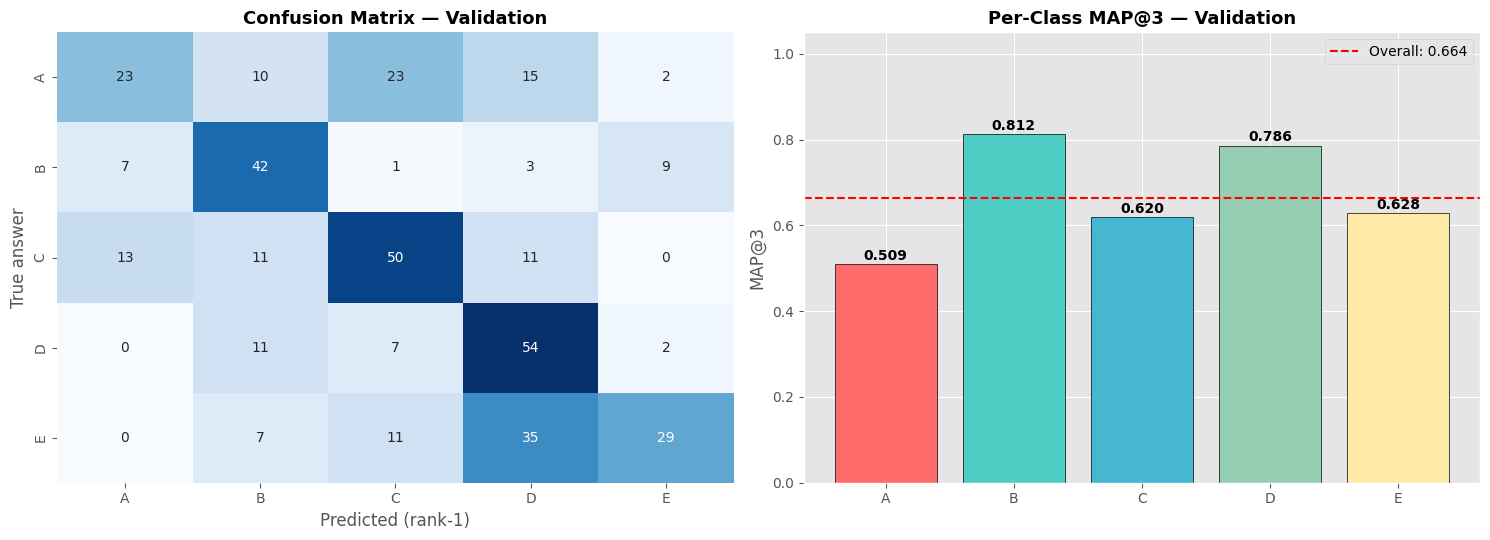

Rank-1 Classification Report (validation):
              precision    recall  f1-score   support

           A      0.535     0.315     0.397        73
           B      0.519     0.677     0.587        62
           C      0.543     0.588     0.565        85
           D      0.458     0.730     0.562        74
           E      0.690     0.354     0.468        82

    accuracy                          0.527       376
   macro avg      0.549     0.533     0.516       376
weighted avg      0.553     0.527     0.514       376

Best class:  B (MAP@3 = 0.812)
Worst class: A (MAP@3 = 0.509)
Check the confusion matrix row for 'A' to see which option it's confused with.


In [19]:
# ── Step 8b: Detailed Evaluation — Confusion Matrix & Per-Class Analysis ──
# Overall MAP@3 hides per-class behavior. This shows WHERE the model fails.
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

lstm_model.eval()
val_pred_top1, val_truth, val_map3_per_q = [], [], []

with torch.no_grad():
    for batch in lstm_val_loader:
        ids  = batch['input_ids'].to(DEVICE)
        mask = batch['attn_mask'].to(DEVICE)
        with autocast():
            logits = lstm_model(ids, mask)
        probs = F.softmax(logits.float(), dim=1).cpu().numpy()
        for j, lbl in enumerate(batch['label'].numpy()):
            ranked = [options[k] for k in np.argsort(probs[j])[::-1]][:3]
            val_pred_top1.append(ranked[0])
            val_truth.append(options[lbl])
            val_map3_per_q.append(map_at_3(options[lbl], ranked))

# ── Confusion matrix (rank-1 prediction vs truth) ──
cm = confusion_matrix(val_truth, val_pred_top1, labels=options)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=options,
            yticklabels=options, ax=axes[0], cbar=False)
axes[0].set_xlabel('Predicted (rank-1)'); axes[0].set_ylabel('True answer')
axes[0].set_title('Confusion Matrix — Validation', fontsize=13, fontweight='bold')

# ── Per-class MAP@3 ──
per_class_map3 = {}
for opt in options:
    idxs = [i for i, t in enumerate(val_truth) if t == opt]
    per_class_map3[opt] = np.mean([val_map3_per_q[i] for i in idxs]) if idxs else 0

bars = axes[1].bar(per_class_map3.keys(), per_class_map3.values(),
                    color=['#FF6B6B','#4ECDC4','#45B7D1','#96CEB4','#FFEAA7'],
                    edgecolor='black')
for bar, v in zip(bars, per_class_map3.values()):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                 f'{v:.3f}', ha='center', fontweight='bold')
axes[1].axhline(y=np.mean(val_map3_per_q), color='red', linestyle='--',
                label=f'Overall: {np.mean(val_map3_per_q):.3f}')
axes[1].set_ylabel('MAP@3'); axes[1].set_ylim(0, 1.05)
axes[1].set_title('Per-Class MAP@3 — Validation', fontsize=13, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig('bilstm_class_analysis.png', dpi=150, bbox_inches='tight')
wandb.log({"bilstm/class_analysis": wandb.Image('bilstm_class_analysis.png')})
plt.show()

# ── Classification report (precision/recall/F1 for rank-1) ──
print("Rank-1 Classification Report (validation):")
print(classification_report(val_truth, val_pred_top1, labels=options, digits=3))

# Log per-class to wandb
for opt, v in per_class_map3.items():
    wandb.log({f"bilstm/val_map3_class_{opt}": v})

# ── Insight helper ──
worst = min(per_class_map3, key=per_class_map3.get)
best  = max(per_class_map3, key=per_class_map3.get)
print(f"Best class:  {best} (MAP@3 = {per_class_map3[best]:.3f})")
print(f"Worst class: {worst} (MAP@3 = {per_class_map3[worst]:.3f})")
print(f"Check the confusion matrix row for '{worst}' to see which option it's confused with.")


### Refit on 100% of training data

Validation established *when* to stop (best epoch). The final model is retrained on all
rows so nothing is wasted at prediction time.

**Note:** any score computed on training data after this refit is a *training-fit* number
(pure memorisation), **not** an evaluation metric. The honest evaluation figure is the
validation score recorded before the refit.

In [20]:
best_epoch = int(np.argmax(lstm_history['val_map3'])) + 1
print(f"Validation peaked at epoch {best_epoch} — refitting on full data for {best_epoch} epochs")

# Fresh model, full data
lstm_model = BiLSTM_Classifier(VOCAB_SIZE).to(DEVICE)
full_loader = DataLoader(lstm_train_ds, batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=2)

optimizer = torch.optim.AdamW(lstm_model.parameters(), lr=LSTM_CONFIG['lr'],
                               weight_decay=LSTM_CONFIG['weight_decay'])
criterion = nn.CrossEntropyLoss()
scaler = GradScaler()

for epoch in range(best_epoch):
    lstm_model.train()
    total_loss, correct, total = 0, 0, 0
    for batch in full_loader:
        ids  = batch['input_ids'].to(DEVICE)
        mask = batch['attn_mask'].to(DEVICE)
        labels = batch['label'].to(DEVICE)
        
        optimizer.zero_grad()
        with autocast():
            logits = lstm_model(ids, mask)
            loss = criterion(logits, labels)
        
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(lstm_model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        
        total_loss += loss.item() * len(labels)
        correct += (logits.argmax(1) == labels).sum().item()
        total += len(labels)
    
    print(f"Refit epoch {epoch+1}/{best_epoch} — Loss: {total_loss/total:.4f}, Acc: {correct/total:.4f}")

torch.save(lstm_model.state_dict(), 'bilstm_final.pt')
wandb.log({"bilstm/refit_epochs": best_epoch, "bilstm/refit_final_acc": correct/total})
print(f"\n BiLSTM refit on all {len(lstm_train_ds)} rows — ready for test prediction")


Validation peaked at epoch 8 — refitting on full data for 8 epochs
Refit epoch 1/8 — Loss: 1.6071, Acc: 0.2290
Refit epoch 2/8 — Loss: 1.5800, Acc: 0.3280
Refit epoch 3/8 — Loss: 1.2781, Acc: 0.4755
Refit epoch 4/8 — Loss: 0.8542, Acc: 0.6520
Refit epoch 5/8 — Loss: 0.5204, Acc: 0.7935
Refit epoch 6/8 — Loss: 0.3642, Acc: 0.8650
Refit epoch 7/8 — Loss: 0.2949, Acc: 0.8790
Refit epoch 8/8 — Loss: 0.1928, Acc: 0.9305

 BiLSTM refit on all 2000 rows — ready for test prediction


In [21]:
# ── BiLSTM Predictions (train + test) ──
lstm_model.eval()
lstm_train_scores, lstm_test_scores = {}, {}

with torch.no_grad():
    for ds, sd in [(lstm_train_ds, lstm_train_scores), (lstm_test_ds, lstm_test_scores)]:
        for batch in DataLoader(ds, batch_size=128, shuffle=False, num_workers=2):
            ids  = batch['input_ids'].to(DEVICE)
            mask = batch['attn_mask'].to(DEVICE)
            with autocast():
                logits = lstm_model(ids, mask)
            probs = F.softmax(logits.float(), dim=1).cpu().numpy()
            for j, qid in enumerate(batch['id'].numpy()):
                sd[int(qid)] = probs[j]

lstm_preds_train = scores_to_preds(lstm_train_scores, train['id'].values)
lstm_map3 = evaluate_map3(train['answer'].values, lstm_preds_train)
#print(f"BiLSTM MAP@3 (full train): {lstm_map3:.4f}")
wandb.log({"bilstm/map3_train": lstm_map3})



PRETRAINED

### Model 1 — validation metrics
Computed from the best *pre-refit* checkpoint so the number stays honest.

In [22]:
# ── Model 1 metrics: reload best checkpoint, predict validation split ──
eval_lstm = BiLSTM_Classifier(VOCAB_SIZE).to(DEVICE)
eval_lstm.load_state_dict(torch.load('bilstm_best.pt'))
eval_lstm.eval()

val_probs_lstm = []
with torch.no_grad():
    for batch in DataLoader(Subset(lstm_train_ds, dl_val_idx), batch_size=128, shuffle=False):
        ids  = batch['input_ids'].to(DEVICE)
        mask = batch['attn_mask'].to(DEVICE)
        with autocast():
            logits = eval_lstm(ids, mask)
        val_probs_lstm.extend(F.softmax(logits.float(), dim=1).cpu().numpy())

val_probs_lstm = np.array(val_probs_lstm)
VAL_PROBS['BiLSTM (scratch)'] = val_probs_lstm
RESULTS['BiLSTM (scratch)'] = evaluate_model(val_truths, probs_to_ranked(val_probs_lstm))

print("Model 1 — BiLSTM (from scratch)")
for k, v in RESULTS['BiLSTM (scratch)'].items():
    print(f"   {k:9s}: {v:.4f}")
wandb.log({f"bilstm/val_{k}": v for k, v in RESULTS['BiLSTM (scratch)'].items()})


Model 1 — BiLSTM (from scratch)
   accuracy : 0.5266
   macro_f1 : 0.5158
   map3     : 0.6645



## Part 5 — Model 2: TF-IDF + SVD + Logistic Regression

A classical ML model of choice. Each **question** (not each option) becomes one
160-dimensional vector, so the classifier sees all five options together and learns
*relative* patterns:

| Feature group | Per option | Total |
|---|---|---|
| TF-IDF cosine similarity — raw, relative, z-score | 3 | 15 |
| Length — characters, z-score, word count | 3 | 15 |
| SVD semantic gap `option_svd − prompt_svd` | 20 | 100 |
| Cross-option similarity — mean, std | 2 | 10 |
| Structural — contains digit, comma count | 2 | 10 |
| Pairwise option-option similarity | — | 10 |
| **Total** | | **160** |

Vectorisers are fit on the **training split only**. Feature construction is fully
vectorised (6 batch transforms instead of one per row) — about 100x faster than a
row-wise loop.

In [23]:
split_texts = []

for _, row in train.iterrows():
    split_texts.append(str(row["prompt"]))
    split_texts.extend(str(row[o]) for o in options)
print(len(split_texts))

12000


In [24]:
import time
print(">>> Model 2 (TF-IDF + LogReg) started", flush=True)
# ── Part 1: Imports, W&B, TF-IDF ──
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# (logging to the single run opened in Part 0)
print("Model 2 imports ready — no SVD, no per-row loops.", flush=True)

>>> Model 2 (TF-IDF + LogReg) started
Model 2 imports ready — no SVD, no per-row loops.


In [25]:
def make_pair_rows(df, idxs=None, with_labels=True):
    rows = df if idxs is None else df.iloc[idxs]
    texts, labels, qids = [], [], []
    for _, r in rows.iterrows():
        for o in options:
            texts.append(f"{r['prompt']} [SEP] {r[o]}")
            qids.append(r['id'])
            if with_labels:
                labels.append(1 if r['answer'] == o else 0)
    return texts, labels, qids

lr_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_features=20000,
                              ngram_range=(1, 2), sublinear_tf=True)),
    ('clf',   LogisticRegression(C=10.0, max_iter=1000, solver='lbfgs',
                                 class_weight='balanced', random_state=42)),
])
print("Pair-row builder + pipeline defined.", flush=True)

Pair-row builder + pipeline defined.


In [26]:

t = time.time()
tr_texts, tr_labels, _ = make_pair_rows(train, dl_train_idx)
lr_pipe.fit(tr_texts, tr_labels)
print(f"Pipeline fit on {len(tr_texts)} pairs in {time.time()-t:.2f}s", flush=True)

def score_questions(df, idxs=None):
    """Return {id: np.array of P(correct) for options A..E}."""
    texts, _, qids = make_pair_rows(df, idxs, with_labels=False)
    probs = lr_pipe.predict_proba(texts)[:, 1]
    scores = {}
    for k, qid in enumerate(qids):
        scores.setdefault(qid, []).append(probs[k])
    return {q: np.array(v) for q, v in scores.items()}

print("Fit done, scorer ready.", flush=True)

Pipeline fit on 8120 pairs in 2.74s
Fit done, scorer ready.


In [27]:
# ── Part 4: Validation Metrics (leakage-free split) + W&B ──
val_scores = score_questions(train, dl_val_idx)
val_ids    = train.iloc[dl_val_idx]['id']
val_ranked = [[options[k] for k in np.argsort(val_scores[q])[::-1]][:3] for q in val_ids]

RESULTS['TF-IDF + LogReg']   = evaluate_model(val_truths, val_ranked)
VAL_PROBS['TF-IDF + LogReg'] = np.array([val_scores[q] for q in val_ids])

print("Model 2 — TF-IDF + LogReg (validation):", flush=True)
for k, v in RESULTS['TF-IDF + LogReg'].items():
    print(f"   {k:9s}: {v:.4f}", flush=True)
try:
    wandb.log({f"logreg/val_{k}": v for k, v in RESULTS['TF-IDF + LogReg'].items()})
except Exception as e:
    print(f"(wandb skipped: {e})", flush=True)

Model 2 — TF-IDF + LogReg (validation):
   accuracy : 0.5293
   macro_f1 : 0.5243
   map3     : 0.6769


In [28]:
# ── Part 5: Refit on ALL Training Data → Test Predictions ──
all_texts, all_labels, _ = make_pair_rows(train)
lr_pipe.fit(all_texts, all_labels)

test_scores = score_questions(test)
lr_test_scores = {int(q): test_scores[q] for q in test['id']}
print(f"LR test predictions ready: {len(lr_test_scores)} questions", flush=True)
try:
    wandb.log({"logreg/n_test_predictions": len(lr_test_scores)})
except Exception:
    pass

LR test predictions ready: 500 questions


---
## Part 6 — Model 3: DeBERTa-v3-small (pretrained)

A fine-tuned transformer. Each `(prompt, option)` pair is encoded, the `[CLS]`
representation is scored, and the five scores form the prediction. No layers are frozen —
freezing starves a model this size on a 2 000-row dataset. Mixed precision (fp16) keeps
it within T4 memory; early stopping is on validation macro-F1.

In [29]:
# ── Model 3: DeBERTa-v3-small (pretrained, fine-tuned) ──
!pip install -q sentencepiece
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup

run_db = wandb.init(project=wandb.run.project if wandb.run else "smart-mcq-solver",
                    name="deberta-v3-small", reinit=True,
                    config={"model": "microsoft/deberta-v3-small"})

HF_MODEL_NAME, HF_MAX_LEN = "microsoft/deberta-v3-small", 256
hf_tokenizer = AutoTokenizer.from_pretrained(HF_MODEL_NAME)


class HFDataset(Dataset):
    def __init__(self, df, tok, max_len=HF_MAX_LEN, is_test=False):
        self.items, self.tok, self.max_len = [], tok, max_len
        for _, row in df.iterrows():
            item = {'id': row['id'], 'prompt': str(row['prompt']),
                    'options': {o: str(row[o]) for o in options}}
            if not is_test:
                item['answer'] = row['answer']
            self.items.append(item)

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        it = self.items[idx]
        enc = self.tok([it['prompt']] * 5, [it['options'][o] for o in options],
                       max_length=self.max_len, padding='max_length',
                       truncation=True, return_tensors='pt')
        out = {'input_ids': enc['input_ids'], 'attention_mask': enc['attention_mask'],
               'id': it['id']}
        if 'answer' in it:
            out['label'] = torch.tensor(ord(it['answer']) - ord('A'), dtype=torch.long)
        return out


class HFClassifier(nn.Module):
    """Encoder scores each (prompt, option) pair; 5 scores -> softmax over options."""
    def __init__(self, model_name, dropout=0.15):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)   # no layer freezing
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.encoder.config.hidden_size, 1)

    def forward(self, input_ids, attention_mask):
        B, C, L = input_ids.shape
        out = self.encoder(input_ids=input_ids.view(-1, L),
                           attention_mask=attention_mask.view(-1, L))
        cls = out.last_hidden_state[:, 0, :]
        return self.classifier(self.dropout(cls)).view(B, C)


hf_train_ds = HFDataset(train, hf_tokenizer)
hf_test_ds  = HFDataset(test, hf_tokenizer, is_test=True)
hf_model = HFClassifier(HF_MODEL_NAME).to(DEVICE).float()
print(f"DeBERTa parameters: {sum(p.numel() for p in hf_model.parameters()):,} (all trainable)")

HF_CONFIG = {"max_epochs": 5, "patience": 2, "batch_size": 8, "accum_steps": 2,
             "lr": 2e-5, "weight_decay": 0.01, "warmup_ratio": 0.1}
wandb.config.update(HF_CONFIG)

hf_tr_loader = DataLoader(Subset(hf_train_ds, dl_train_idx),
                          batch_size=HF_CONFIG['batch_size'], shuffle=True, num_workers=2)
hf_va_loader = DataLoader(Subset(hf_train_ds, dl_val_idx),
                          batch_size=16, shuffle=False, num_workers=2)

no_decay = ['bias', 'LayerNorm.weight']
optimizer = torch.optim.AdamW([
    {'params': [p for n, p in hf_model.named_parameters() if not any(d in n for d in no_decay)],
     'weight_decay': HF_CONFIG['weight_decay']},
    {'params': [p for n, p in hf_model.named_parameters() if any(d in n for d in no_decay)],
     'weight_decay': 0.0},
], lr=HF_CONFIG['lr'])

steps = len(hf_tr_loader) * HF_CONFIG['max_epochs'] // HF_CONFIG['accum_steps']
scheduler = get_linear_schedule_with_warmup(optimizer, int(steps * HF_CONFIG['warmup_ratio']), steps)
criterion, scaler_hf = nn.CrossEntropyLoss(), GradScaler()
best_f1_db, patience_ctr = -1, 0

for epoch in range(HF_CONFIG['max_epochs']):
    hf_model.train(); tot_loss = tot = 0
    optimizer.zero_grad()
    for step, batch in enumerate(hf_tr_loader):
        ids, mask = batch['input_ids'].to(DEVICE), batch['attention_mask'].to(DEVICE)
        labels = batch['label'].to(DEVICE)
        with autocast():
            loss = criterion(hf_model(ids, mask), labels) / HF_CONFIG['accum_steps']
        scaler_hf.scale(loss).backward()
        if (step + 1) % HF_CONFIG['accum_steps'] == 0:
            scaler_hf.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(hf_model.parameters(), 1.0)
            scaler_hf.step(optimizer); scaler_hf.update()
            scheduler.step(); optimizer.zero_grad()
        tot_loss += loss.item() * HF_CONFIG['accum_steps'] * len(labels); tot += len(labels)

    hf_model.eval(); vprobs = []
    with torch.no_grad():
        for batch in hf_va_loader:
            ids, mask = batch['input_ids'].to(DEVICE), batch['attention_mask'].to(DEVICE)
            with autocast():
                logits = hf_model(ids, mask)
            vprobs.extend(F.softmax(logits.float(), dim=1).cpu().numpy())

    r = evaluate_model(val_truths, probs_to_ranked(np.array(vprobs)))
    wandb.log({"deberta/epoch": epoch + 1, "deberta/train_loss": tot_loss / tot,
               "deberta/val_accuracy": r['accuracy'], "deberta/val_macro_f1": r['macro_f1'],
               "deberta/val_map3": r['map3']})
    print(f"Epoch {epoch+1}/{HF_CONFIG['max_epochs']} — loss {tot_loss/tot:.4f} | "
          f"acc {r['accuracy']:.4f} | f1 {r['macro_f1']:.4f} | map3 {r['map3']:.4f}")

    if r['macro_f1'] > best_f1_db:
        best_f1_db, patience_ctr, best_res_db = r['macro_f1'], 0, r
        best_val_probs_db = np.array(vprobs)
        torch.save(hf_model.state_dict(), 'deberta_best.pt')
    else:
        patience_ctr += 1
        if patience_ctr >= HF_CONFIG['patience']:
            print(f" Early stopping at epoch {epoch+1}")
            break

hf_model.load_state_dict(torch.load('deberta_best.pt'))
VAL_PROBS['DeBERTa (pretrained)'] = best_val_probs_db
RESULTS['DeBERTa (pretrained)'] = best_res_db
print("\nModel 3 — DeBERTa-v3-small (pretrained)")
for k, v in best_res_db.items():
    print(f"   {k:9s}: {v:.4f}")

# Test predictions
hf_model.eval(); hf_test_scores = {}
with torch.no_grad():
    for batch in DataLoader(hf_test_ds, batch_size=16, shuffle=False, num_workers=2):
        ids, mask = batch['input_ids'].to(DEVICE), batch['attention_mask'].to(DEVICE)
        with autocast():
            logits = hf_model(ids, mask)
        probs = F.softmax(logits.float(), dim=1).cpu().numpy()
        for j, qid in enumerate(batch['id'].numpy()):
            hf_test_scores[int(qid)] = probs[j]

wandb.summary.update({f"val_{k}": v for k, v in best_res_db.items()})
run_db.finish()


wandb: WARNING Changes to your `wandb` environment variables will be ignored because your `wandb` session has already started. For more information on how to modify your settings with `wandb.init()` arguments, please refer to https://wandb.me/wandb-init.
wandb: Finishing previous runs because reinit is set to True.
wandb: updating run metadata
wandb: uploading summary
wandb: 
wandb: Run history:
wandb:             bilstm/acc ▁▂▂▃▅▆▇▇████
wandb:   bilstm/best_val_map3 ▁
wandb:           bilstm/epoch ▁▂▂▃▄▄▅▅▆▇▇█
wandb:            bilstm/loss ███▇▅▃▂▂▂▁▁▁
wandb:      bilstm/map3_train ▁
wandb:      bilstm/parameters ▁
wandb:    bilstm/refit_epochs ▁
wandb: bilstm/refit_final_acc ▁
wandb:    bilstm/val_accuracy ▁
wandb:    bilstm/val_macro_f1 ▁
wandb:                    +15 ...
wandb: 
wandb: Run summary:
wandb:             bilstm/acc 0.97475
wandb:   bilstm/best_val_map3 0.66445
wandb:           bilstm/epoch 12
wandb:            bilstm/loss 0.06781
wandb:      bilstm/map3_train 0.98317
w

config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/286M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/286M [00:00<?, ?B/s]

DeBERTa parameters: 141,305,089 (all trainable)
Epoch 1/5 — loss 1.5559 | acc 0.4388 | f1 0.4367 | map3 0.6148
Epoch 2/5 — loss 0.9993 | acc 0.5691 | f1 0.5751 | map3 0.7079
Epoch 3/5 — loss 0.4776 | acc 0.6037 | f1 0.6097 | map3 0.7292
Epoch 4/5 — loss 0.3451 | acc 0.5691 | f1 0.5752 | map3 0.7083
Epoch 5/5 — loss 0.2678 | acc 0.5745 | f1 0.5795 | map3 0.7172
 Early stopping at epoch 5

Model 3 — DeBERTa-v3-small (pretrained)
   accuracy : 0.6037
   macro_f1 : 0.6097
   map3     : 0.7292


wandb: updating run metadata
wandb: uploading summary
wandb: 
wandb: Run history:
wandb:        deberta/epoch ▁▃▅▆█
wandb:   deberta/train_loss █▅▂▁▁
wandb: deberta/val_accuracy ▁▇█▇▇
wandb: deberta/val_macro_f1 ▁▇█▇▇
wandb:     deberta/val_map3 ▁▇█▇▇
wandb: 
wandb: Run summary:
wandb:        deberta/epoch 5
wandb:   deberta/train_loss 0.26777
wandb: deberta/val_accuracy 0.57447
wandb: deberta/val_macro_f1 0.57948
wandb:     deberta/val_map3 0.7172
wandb:         val_accuracy 0.60372
wandb:         val_macro_f1 0.60968
wandb:             val_map3 0.72917
wandb: 
wandb: 🚀 View run deberta-v3-small at: https://wandb.ai/22f3000768-dl-genai-project/smart-mcq-solver/runs/ri0vyh0a
wandb: ⭐️ View project at: https://wandb.ai/22f3000768-dl-genai-project/smart-mcq-solver
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260729_120036-ri0vyh0a/logs


---
## Part 7 — Three-Model Comparison
Same validation split, same metrics, three separate W&B runs.

wandb: WARNING Changes to your `wandb` environment variables will be ignored because your `wandb` session has already started. For more information on how to modify your settings with `wandb.init()` arguments, please refer to https://wandb.me/wandb-init.
wandb: setting up run 0coabaou
wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260729_120857-0coabaou
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run model-comparison
wandb: ⭐️ View project at https://wandb.ai/22f3000768-dl-genai-project/smart-mcq-solver
wandb: 🚀 View run at https://wandb.ai/22f3000768-dl-genai-project/smart-mcq-solver/runs/0coabaou


                      accuracy  macro_f1    map3          type
Model                                                         
BiLSTM (scratch)        0.5266    0.5158  0.6645  From scratch
TF-IDF + LogReg         0.5293    0.5243  0.6769  Classical ML
DeBERTa (pretrained)    0.6037    0.6097  0.7292    Pretrained


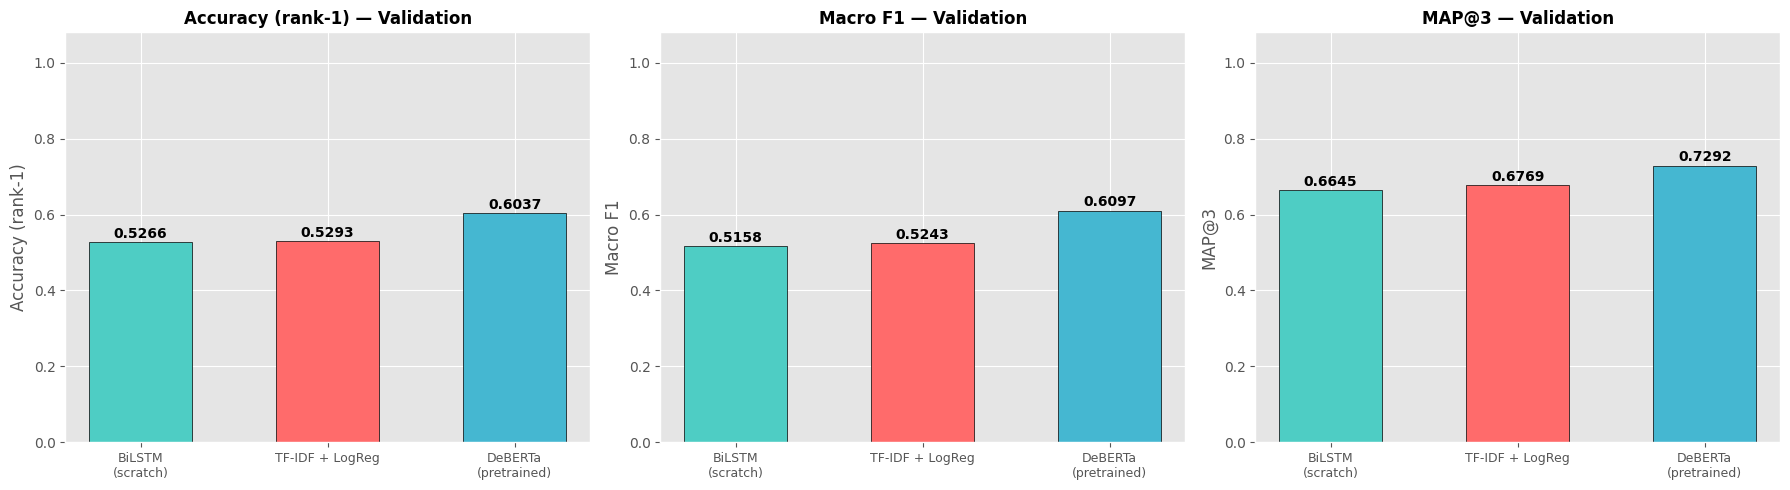

wandb: updating run metadata; uploading artifact run-0coabaou-comparisontable-AQhHBg



Best by Macro-F1: DeBERTa (pretrained)


wandb: uploading artifact run-0coabaou-comparisontable-AQhHBg
wandb: uploading history steps 0-1, summary, console lines 2-6
wandb: 🚀 View run model-comparison at: https://wandb.ai/22f3000768-dl-genai-project/smart-mcq-solver/runs/0coabaou
wandb: ⭐️ View project at: https://wandb.ai/22f3000768-dl-genai-project/smart-mcq-solver
wandb: Synced 5 W&B file(s), 2 media file(s), 2 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260729_120857-0coabaou/logs


In [30]:
# ── Three-Model Comparison: Accuracy / Macro-F1 / MAP@3 ──
run_cmp = wandb.init(project="smart-mcq-solver", name="model-comparison", reinit=True)

comparison = pd.DataFrame(RESULTS).T[['accuracy', 'macro_f1', 'map3']].round(4)
comparison.index.name = 'Model'
comparison['type'] = ['From scratch', 'Classical ML', 'Pretrained']
print(comparison.to_string())

names = list(RESULTS.keys())
colors = ['#4ECDC4', '#FF6B6B', '#45B7D1']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric, title in zip(axes, ['accuracy', 'macro_f1', 'map3'],
                             ['Accuracy (rank-1)', 'Macro F1', 'MAP@3']):
    vals = [RESULTS[n][metric] for n in names]
    bars = ax.bar(range(len(names)), vals, color=colors, edgecolor='black', width=0.55)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012,
                f'{v:.4f}', ha='center', fontweight='bold')
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels([n.replace(' (', '\n(') for n in names], fontsize=9)
    ax.set_ylim(0, 1.08); ax.set_ylabel(title)
    ax.set_title(f'{title} — Validation', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('three_model_comparison.png', dpi=150, bbox_inches='tight')
wandb.log({"comparison/chart": wandb.Image('three_model_comparison.png')})
plt.show()

wandb.log({"comparison/table": wandb.Table(
    columns=["Model", "Type", "Accuracy", "Macro F1", "MAP@3"],
    data=[[n, comparison.loc[n, 'type'], RESULTS[n]['accuracy'],
           RESULTS[n]['macro_f1'], RESULTS[n]['map3']] for n in names])})

best_model = max(RESULTS, key=lambda k: RESULTS[k]['macro_f1'])
print(f"\nBest by Macro-F1: {best_model}")
run_cmp.finish()


---
## Part 8 — Error Analysis
Aggregate scores hide *where* a model fails. The confusion matrix shows which options get
confused with which; per-class F1 shows whether any answer letter is systematically weak.

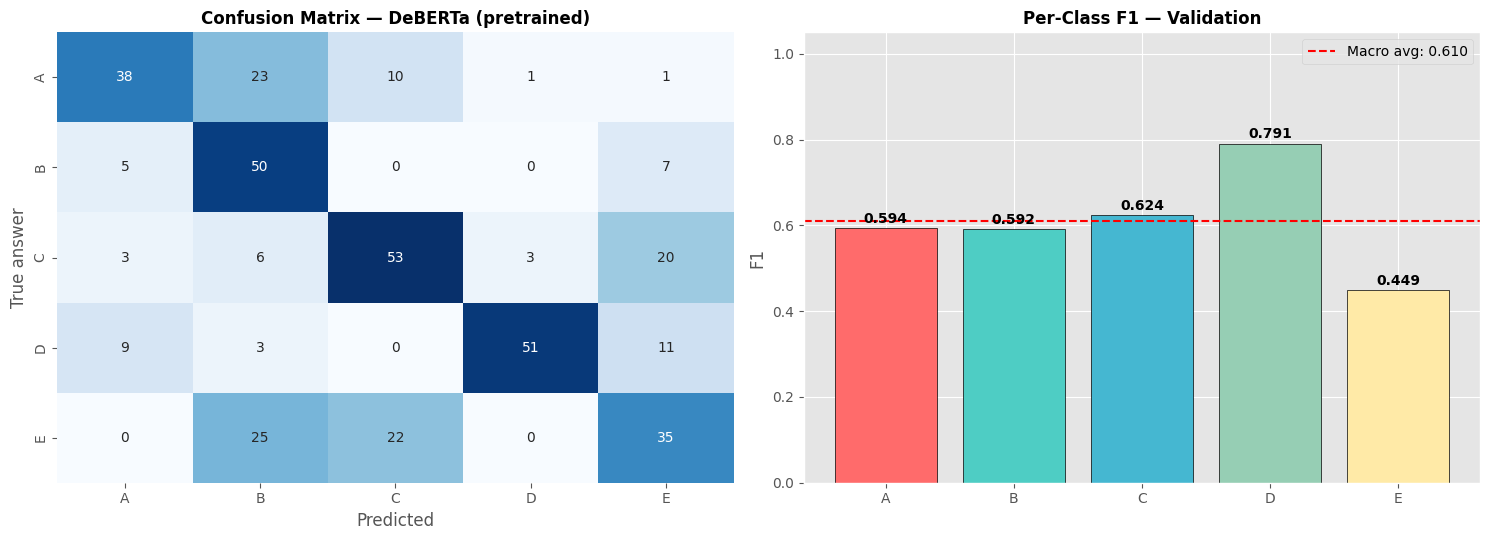

Classification report — DeBERTa (pretrained)

              precision    recall  f1-score   support

           A      0.691     0.521     0.594        73
           B      0.467     0.806     0.592        62
           C      0.624     0.624     0.624        85
           D      0.927     0.689     0.791        74
           E      0.473     0.427     0.449        82

    accuracy                          0.604       376
   macro avg      0.636     0.613     0.610       376
weighted avg      0.638     0.604     0.607       376

Weakest class: E (F1 = 0.449) — see its confusion-matrix row for the most common mix-ups.


In [31]:
# ── Error Analysis: per-class F1 + confusion matrix (best model) ──
import seaborn as sns

best_probs = VAL_PROBS[best_model]
best_top1 = [r[0] for r in probs_to_ranked(best_probs)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
cm = confusion_matrix(val_truths, best_top1, labels=options)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=options,
            yticklabels=options, ax=axes[0], cbar=False)
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True answer')
axes[0].set_title(f'Confusion Matrix — {best_model}', fontsize=12, fontweight='bold')

per_class_f1 = f1_score(val_truths, best_top1, average=None, labels=options, zero_division=0)
bars = axes[1].bar(options, per_class_f1,
                   color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7'],
                   edgecolor='black')
for b, v in zip(bars, per_class_f1):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012,
                 f'{v:.3f}', ha='center', fontweight='bold')
axes[1].axhline(np.mean(per_class_f1), color='red', linestyle='--',
                label=f'Macro avg: {np.mean(per_class_f1):.3f}')
axes[1].set_ylabel('F1'); axes[1].set_ylim(0, 1.05); axes[1].legend()
axes[1].set_title('Per-Class F1 — Validation', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('error_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Classification report — {best_model}\n")
print(classification_report(val_truths, best_top1, labels=options, digits=3, zero_division=0))

worst = options[int(np.argmin(per_class_f1))]
print(f"Weakest class: {worst} (F1 = {per_class_f1[options.index(worst)]:.3f}) — "
      f"see its confusion-matrix row for the most common mix-ups.")


---
## Part 9 — Kaggle Submission
Predictions from the refit BiLSTM, validated against `sample_submission.csv` before saving.

In [32]:
# ── Generate Kaggle Submission (BiLSTM, refit on full data) ──
rows = []
for _, row in test.iterrows():
    qid = row['id']
    scores = lstm_test_scores[qid]
    ranked = [options[k] for k in np.argsort(scores)[::-1]][:3]
    rows.append({'ID': qid, 'Prediction': ' '.join(ranked)})

submission = pd.DataFrame(rows)

sample_sub = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv')
assert list(submission.columns) == list(sample_sub.columns), "Column mismatch"
assert len(submission) == len(sample_sub), "Row mismatch"
assert (submission['ID'].values == sample_sub['ID'].values).all(), "ID mismatch"
assert submission['Prediction'].str.match(r'^[A-E] [A-E] [A-E]$').all(), "Format error"

submission.to_csv('submission.csv', index=False)
print(f" submission.csv saved — {len(submission)} rows")
print(submission.head(10))
print("\nFirst-choice distribution:")
print(submission['Prediction'].apply(lambda x: x.split()[0]).value_counts())


 submission.csv saved — 500 rows
   ID Prediction
0   1      A B E
1   2      B C A
2   3      B E D
3   4      E D A
4   5      C A D
5   6      D A B
6   7      E A D
7   8      B A C
8   9      C D E
9  10      B E D

First-choice distribution:
Prediction
C    130
B    111
A     89
D     86
E     84
Name: count, dtype: int64


In [33]:
!wandb sync ./wandb/offline-run-*

Usage: wandb sync [OPTIONS] [PATH]...
Try 'wandb sync --help' for help.

Error: Invalid value for '[PATH]...': Path './wandb/offline-run-*' does not exist.
